In [20]:
import komamripy as km
import numpy as np
import matplotlib.pyplot as plt
# km.load_amdgpu()

In [21]:
# Create Simulation Inputs
sys = km.Scanner()  # need to change to discovery mr750w 3t scanner
obj = km.brain_phantom2D()  # fine for now
obj.Δw = np.zeros_like(obj.Δw)
# seq = km.PulseDesigner.EPI_example()
seq = km.files.read_seq("../sequences/simple_epi.seq") # 

# Run Simulation
sim_params = {"return_type": "mat"}
raw = km.simulate(obj, seq, sys, sim_params=sim_params)

[ Info: Loading sequence simple_epi.seq ...
┌ Info: Running simulation in the CPU with 1 thread(s)
│   koma_version = v"0.14.0"
│   sim_method = Bloch()
│   spins = 6506
│   time_points = 4557
└   adc_points = 4096
Running simulation...  27%|███████▉                     |  ETA: 0:00:00
   simulated_blocks: 3
          rf_blocks: 1
     acq_samples: 458


Running simulation...  45%|█████████████▏               |  ETA: 0:00:00
   simulated_blocks: 5
          rf_blocks: 1


Running simulation...  64%|██████████████████▌          |  ETA: 0:00:00
   simulated_blocks: 7
          rf_blocks: 1
     acq_samples: 2332


Running simulation...  82%|███████████████████████▊     |  ETA: 0:00:00
   simulated_blocks: 9
          rf_blocks: 1
     acq_samples: 3266


Running simulation... 100%|█████████████████████████████| Time: 0:00:00
   simulated_blocks: 11
          rf_blocks: 1
        acq_samples: 4096


  0.678018 seconds (97.88 k allocations: 16.621 MiB)


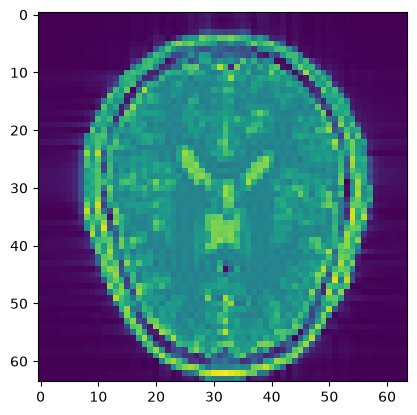

In [22]:
# Extract kdata
mat_size = int(np.sqrt(np.asarray(raw).size))
data = np.asarray(raw).squeeze().reshape(mat_size, mat_size)
data[1::2] = data[1::2, ::-1] # data is rasterized; need to unrasterize

# Show Image
plt.imshow(np.abs(np.fft.ifftshift(np.fft.ifft2(np.fft.ifftshift(data)))))